In [1]:
# This basic script shows how to use CLASS to plot the CMB spectrum
# of temperature, polarisation and lensing potential, as well as the matter power spectrum

In [2]:
# import classy module
from classy import Class
from numpy import pi

In [3]:
# create an instance of CLASS
LambdaCDM = Class()

####################################################
#
# Cosmological parameters and other CLASS parameters
#
####################################################
input = {# LambdaCDM parameters (Planck 18 + lensing + BAO bestfit)
        'hierarchy':'TAM',
        'modes':'s',
        'output':'tCl, pCl',
        'L': 0.001,
        'A': pi,
        }
LambdaCDM.set(input)

# Note that you could get all the same settings in just one line with the pre-set command
# LambdaCDM.set_baseline('p18lb')
# Here 'p18lb' is a short-cut for Planck18 + lensing + BAO bestfit
# other options are 'p18l' and 'p18'
# These pre-settings are defined in the classy function .set_baseline()

# In older versions of classy one needed to execute CLASS with .compute()
# This is no longer necessary, the code execution happens directly when calling classy functions

True

In [4]:
import sys
import classy
from classy import _classy

print(sys.executable)
print(_classy.__file__)
print(LambdaCDM.pars.get('output'))
cls = LambdaCDM.raw_cl(lmax=2500)
print(cls.keys())

/Users/derinsivrioglu/miniconda3/envs/cmbgood/bin/python
/Users/derinsivrioglu/miniconda3/envs/cmbgood/lib/python3.12/site-packages/classy/_classy.cpython-312-darwin.so
tCl, pCl
dict_keys(['tt', 'ee', 'te', 'bb', 'eb', 'tb', 'ell'])


In [5]:
# get lesned C_l spectra
cls = LambdaCDM.raw_cl(2500)
# To check the format of cls
cls.keys()

dict_keys(['tt', 'ee', 'te', 'bb', 'eb', 'tb', 'ell'])

In [6]:
# get multipoles l
ll = cls['ell'][2:]
# get CMB temperature spectrum C_l^TT
clTT = cls['tt'][2:]
# get CMB polarisation spectrum C_l^EE
clEE = cls['ee'][2:]
# get CMB polarisation spectrum C_l^BB
clBB = cls['bb'][2:]
# get CMB cross-polarisation spectrum C_l^EB
clEB = cls['eb'][2:]
# get CMB cross-polarisation spectrum C_l^TB
clTB = cls['tb'][2:]

Text(0, 0.5, '$\\ell(\\ell+1)C_\\ell^{EB}/(2\\pi)$')

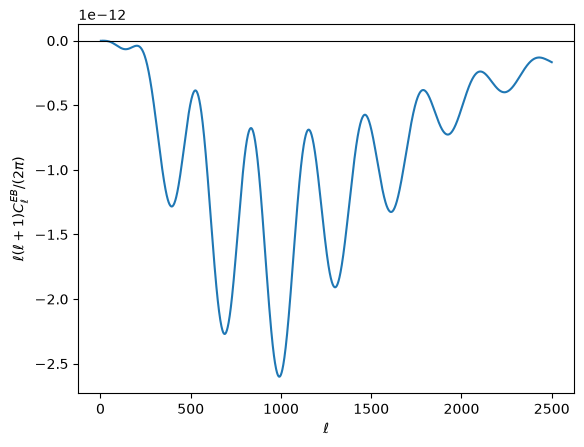

In [22]:
ell = cls["ell"]
cl_eb = cls["eb"]

plt.plot(ell[2:], ell[2:] * (ell[2:] + 1) * cl_eb[2:] / (2 * np.pi))
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel(r"$\ell$")
plt.ylabel(r"$\ell(\ell+1)C_\ell^{EB}/(2\pi)$")

In [7]:
# uncomment to get plots displayed in notebook
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

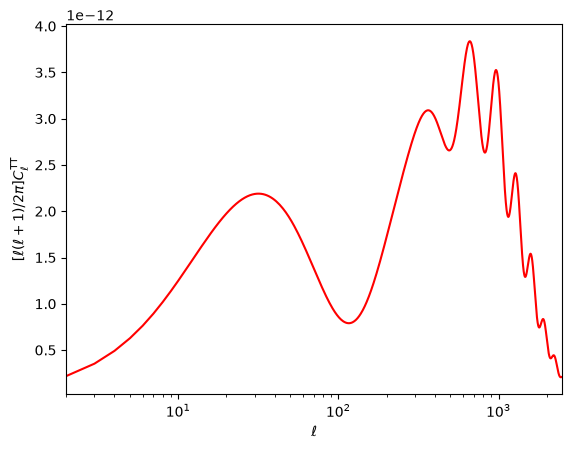

In [8]:
# plot C_l^TT
plt.figure(1)
plt.xscale('log');plt.yscale('linear');plt.xlim(2,2500)
plt.xlabel(r'$\ell$')
plt.ylabel(r'$[\ell(\ell+1)/2\pi]  C_\ell^\mathrm{TT}$')
plt.plot(ll,clTT*ll*(ll+1)/(2.*np.pi),'r-')
plt.savefig('warmup_cltt.pdf')

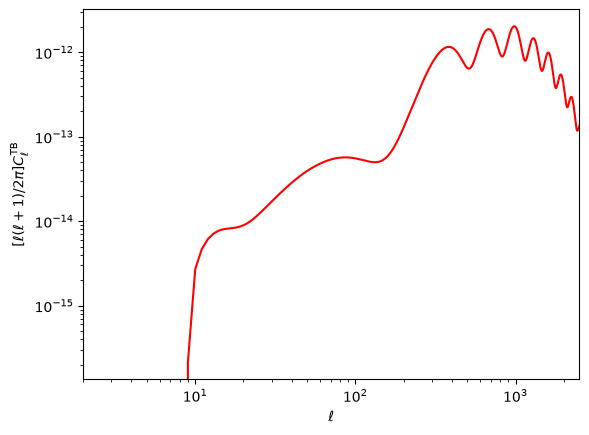

In [19]:
# plot C_l^TB
plt.figure(1)
plt.xscale('log');plt.yscale('log');plt.xlim(2,2500)
plt.xlabel(r'$\ell$')
plt.ylabel(r'$[\ell(\ell+1)/2\pi]  C_\ell^\mathrm{TB}$')
plt.plot(ll,clTB*ll*(ll+1)/(2.*np.pi),'r-')
plt.savefig('warmup_clee.pdf')

/var/folders/g4/8q9hl6y95sd4hpc0lcc6j3_h0000gn/T/ipykernel_13776/3036762680.py:7: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  plt.savefig('warmup_clee.pdf')


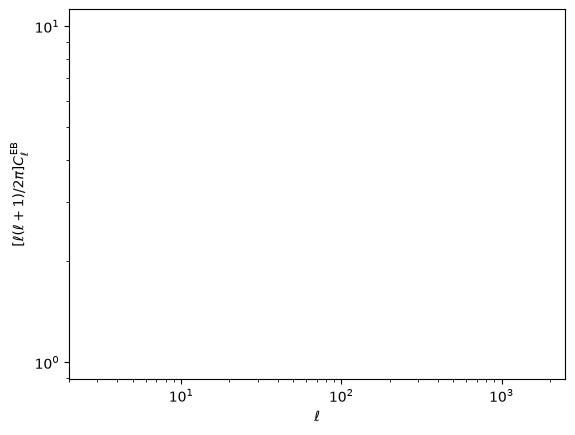

In [20]:
# plot C_l^EB
plt.figure(1)
plt.xscale('log');plt.yscale('log');plt.xlim(2,2500)
plt.xlabel(r'$\ell$')
plt.ylabel(r'$[\ell(\ell+1)/2\pi]  C_\ell^\mathrm{EB}$')
plt.plot(ll,clEB*ll*(ll+1)/(2.*np.pi),'r-')
plt.savefig('warmup_clee.pdf')